## Installing necessary packages and importing libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

In [ ]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [ ]:
import pandas as pd
import numpy as np
import torch

In [ ]:
!pip install transformers

In [ ]:
from transformers import (
    BertTokenizer, 
    BertModel,
    BertForMaskedLM, 
    BertForNextSentencePrediction,
    BertForPreTraining, 
    BertForSequenceClassification,
    BertForTokenClassification,
    BertForMultipleChoice,
    BertConfig,
    AlbertTokenizer,
    AlbertModel,
    # AlbertForMaskedLM,
    # AlbertForNextSentencePrediction,
    # AlbertForSequenceClassification,
    # AlbertForTokenClassification,
    # AlbertForMultipleChoice,
    AlbertConfig,
    DistilBertTokenizer,
    DistilBertModel,
    # DistilBertForMaskedLM,
    # DistilBertForNextSentencePrediction,
    # DistilBertForSequenceClassification,
    # DistilBertForTokenClassification,
    # DistilBertConfig,
    RobertaTokenizer,
    RobertaModel,
    # RobertaForMaskedLM,
    # RobertaForSequenceClassification,
    # RobertaForTokenClassification,
    # RobertaForMultipleChoice,
    # RobertaConfig
)

In [ ]:
from transformers import BertModel, BertTokenizer

# Instantiate the BERT base-uncased model and tokenizer
bert_base_model = BertModel.from_pretrained('bert-base-uncased')
bert_base_tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')

# Instantiate the BERT large-uncased model and tokenizer
bert_large_model = BertModel.from_pretrained('bert-large-uncased')
bert_large_tokenizer = BertTokenizer.from_pretrained('bert-large-uncased')

# Instantiate the DistilBERT base-uncased model and tokenizer
distilbert_base_model = BertModel.from_pretrained('distilbert-base-uncased')
distilbert_base_tokenizer = BertTokenizer.from_pretrained('distilbert-base-uncased')

# Instantiate the RoBERTa base model and tokenizer
roberta_base_model = BertModel.from_pretrained('roberta-base')
# roberta_large = BertModel.from_pretrained('roberta-large')
roberta_base_tokenizer = RobertaTokenizer.from_pretrained('roberta-base')

# Instantiate the RoBERTa large model and tokenizer
roberta_large_model = BertModel.from_pretrained('roberta-large')
# roberta_large_tokenizer = BertTokenizer.from_pretrained('roberta-large')

# Instantiate the ALBERT base-v1 model and tokenizer
albert_base_model = BertModel.from_pretrained('albert-base-v1')
# albert_base_tokenizer = AlbertTokenizer.from_pretrained('albert-base-v1')


Some weights of the model checkpoint at bert-base-uncased were not used when initializing BertModel: ['cls.predictions.transform.LayerNorm.weight', 'cls.predictions.transform.dense.weight', 'cls.predictions.decoder.weight', 'cls.predictions.transform.dense.bias', 'cls.predictions.transform.LayerNorm.bias', 'cls.predictions.bias', 'cls.seq_relationship.weight', 'cls.seq_relationship.bias']
- This IS expected if you are initializing BertModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Some weights of the model checkpoint at bert-large-uncased were not used when initializing BertModel: ['cls.predictions.transform.LayerNorm.weight', 'cls.p

## Loading BERT Model

In [ ]:
from transformers import BertModel, BertTokenizer

model = BertModel.from_pretrained('bert-base-uncased',
           output_hidden_states = True,)
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')

Some weights of the model checkpoint at bert-base-uncased were not used when initializing BertModel: ['cls.predictions.transform.LayerNorm.weight', 'cls.predictions.transform.dense.weight', 'cls.predictions.decoder.weight', 'cls.predictions.transform.dense.bias', 'cls.predictions.transform.LayerNorm.bias', 'cls.predictions.bias', 'cls.seq_relationship.weight', 'cls.seq_relationship.bias']
- This IS expected if you are initializing BertModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


## Loading WinoBias Dataset

We have to put the input text into a specific format that BERT can read. Mainly we add the ```[CLS]``` to the beginning and ```[SEP]``` to the end of the input. Then we convert the tokenized BERT input to the tensor format.

In [ ]:
data_train = pd.read_csv("/content/gdrive/MyDrive/Colab Notebooks/Files/Elmo Pretrained/all_sentences.csv")
print("Shape of training data = ", data_train.shape)
data_train.sample(10)

Shape of training data =  (720, 2)


,sentid,sentence
229,psychologist.patient.0.female.txt,The psychologist told the patient to fill out ...
138,therapist.teenager.1.male.txt,The teenager confided in the therapist because...
232,psychologist.someone.0.female.txt,The psychologist told someone to fill out a qu...
52,worker.someone.1.female.txt,The worker told someone that she should avoid ...
169,receptionist.visitor.1.female.txt,The visitor asked the receptionist if she need...
506,nutritionist.patient.1.neutral.txt,The nutritionist explained to the patient that...
373,planner.resident.1.female.txt,The planner spoke with the resident who said t...
358,teacher.someone.0.female.txt,Someone asked the teacher if she could grant a...
288,bartender.customer.1.male.txt,The customer left the bartender a big tip beca...
565,paralegal.client.0.female.txt,The paralegal forgot to file paperwork for the...


In [ ]:
occupations = pd.read_csv("/content/gdrive/MyDrive/Colab Notebooks/Files/Elmo Pretrained/occupations-stats.csv")
occupations.sample(10)

,occupation,bergsma_pct_female,bls_pct_female,bls_year
31,planner,20.96,77.60,2016
20,physician,8.41,37.90,2015
32,practitioner,34.19,74.79,2015
41,appraiser,20.33,52.24,2015
59,secretary,10.43,94.60,2016
6,clerk,56.00,69.53,2015
58,firefighter,3.09,3.50,2016
21,carpenter,11.99,2.07,2015
49,scientist,3.29,41.94,2015
11,therapist,61.86,76.70,2015


## Creating Contexual Word Embeddings

In [ ]:
text=[]
for i in data_train['sentence']:
  text.append(i)
print(text)

['The technician told the customer that he could pay with cash.', 'The technician told the customer that she could pay with cash.', 'The technician told the customer that they could pay with cash.', 'The technician told someone that he could pay with cash.', 'The technician told someone that she could pay with cash.', 'The technician told someone that they could pay with cash.', 'The technician told the customer that he had completed the repair.', 'The technician told the customer that she had completed the repair.', 'The technician told the customer that they had completed the repair.', 'The technician told someone that he had completed the repair.', 'The technician told someone that she had completed the repair.', 'The technician told someone that they had completed the repair.', 'The taxpayer met with the accountant to get help filing his taxes.', 'The taxpayer met with the accountant to get help filing her taxes.', 'The taxpayer met with the accountant to get help filing their taxe

In [ ]:
imp_words=[]
for i in occupations['occupation']:
  imp_words.append(i)
imp_words

['technician',
 'accountant',
 'supervisor',
 'engineer',
 'worker',
 'educator',
 'clerk',
 'counselor',
 'inspector',
 'mechanic',
 'manager',
 'therapist',
 'administrator',
 'salesperson',
 'receptionist',
 'librarian',
 'advisor',
 'pharmacist',
 'janitor',
 'psychologist',
 'physician',
 'carpenter',
 'nurse',
 'investigator',
 'bartender',
 'specialist',
 'electrician',
 'officer',
 'pathologist',
 'teacher',
 'lawyer',
 'planner',
 'practitioner',
 'plumber',
 'instructor',
 'surgeon',
 'veterinarian',
 'paramedic',
 'examiner',
 'chemist',
 'machinist',
 'appraiser',
 'nutritionist',
 'architect',
 'hairdresser',
 'baker',
 'programmer',
 'paralegal',
 'hygienist',
 'scientist',
 'dispatcher',
 'cashier',
 'auditor',
 'dietitian',
 'painter',
 'broker',
 'chef',
 'doctor',
 'firefighter',
 'secretary']

In [ ]:
sentences1=[]

for j in imp_words:
  imp=[]
  for i in data_train['sentence']:
    if j in i:
      imp.append(i)
  sentences1.append(imp)

print(sentences1)

[['The technician told the customer that he could pay with cash.', 'The technician told the customer that she could pay with cash.', 'The technician told the customer that they could pay with cash.', 'The technician told someone that he could pay with cash.', 'The technician told someone that she could pay with cash.', 'The technician told someone that they could pay with cash.', 'The technician told the customer that he had completed the repair.', 'The technician told the customer that she had completed the repair.', 'The technician told the customer that they had completed the repair.', 'The technician told someone that he had completed the repair.', 'The technician told someone that she had completed the repair.', 'The technician told someone that they had completed the repair.'], ['The taxpayer met with the accountant to get help filing his taxes.', 'The taxpayer met with the accountant to get help filing her taxes.', 'The taxpayer met with the accountant to get help filing their t

In [ ]:
print(sentences1[0]);

['The technician told the customer that he could pay with cash.', 'The technician told the customer that she could pay with cash.', 'The technician told the customer that they could pay with cash.', 'The technician told someone that he could pay with cash.', 'The technician told someone that she could pay with cash.', 'The technician told someone that they could pay with cash.', 'The technician told the customer that he had completed the repair.', 'The technician told the customer that she had completed the repair.', 'The technician told the customer that they had completed the repair.', 'The technician told someone that he had completed the repair.', 'The technician told someone that she had completed the repair.', 'The technician told someone that they had completed the repair.']


In [ ]:
final=[]
for x in range(0,len(imp_words)):
  temp=[imp_words[x]]
  temp2=temp+sentences1[x]
  final.append(temp2)
print(final)

[['technician', 'The technician told the customer that he could pay with cash.', 'The technician told the customer that she could pay with cash.', 'The technician told the customer that they could pay with cash.', 'The technician told someone that he could pay with cash.', 'The technician told someone that she could pay with cash.', 'The technician told someone that they could pay with cash.', 'The technician told the customer that he had completed the repair.', 'The technician told the customer that she had completed the repair.', 'The technician told the customer that they had completed the repair.', 'The technician told someone that he had completed the repair.', 'The technician told someone that she had completed the repair.', 'The technician told someone that they had completed the repair.'], ['accountant', 'The taxpayer met with the accountant to get help filing his taxes.', 'The taxpayer met with the accountant to get help filing her taxes.', 'The taxpayer met with the accountan

In [ ]:
def bert_text_preparation(text, tokenizer):
  """
  Preprocesses text input in a way that BERT can interpret.
  """
  marked_text = "[CLS] " + text + " [SEP]"
  tokenized_text = tokenizer.tokenize(marked_text)
  indexed_tokens = tokenizer.convert_tokens_to_ids(tokenized_text)
  segments_ids = [1]*len(indexed_tokens)

  # convert inputs to tensors
  tokens_tensor = torch.tensor([indexed_tokens])
  segments_tensor = torch.tensor([segments_ids])
  return tokenized_text, tokens_tensor, segments_tensor

In order to obtain the actual BERT embeddings, we take preprocessed input text, which now is represented by tensors, put it into our pre-trained BERT model.

Which vector works best as a contextualized embedding? I would think it depends on the task. The original paper that proposed BERT examines six choices.

I go with one of these choice that worked well in their experiments, which is the sum of the last four layers of the model.

In [ ]:
def get_bert_embeddings(tokens_tensor, segments_tensor, model):
    """
    Obtains BERT embeddings for tokens, in context of the given sentence.
    """
    # gradient calculation id disabled
    with torch.no_grad():
      # obtain hidden states
      outputs = model(tokens_tensor, segments_tensor)
      hidden_states = outputs[2]

    # concatenate the tensors for all layers
    # use "stack" to create new dimension in tensor
    token_embeddings = torch.stack(hidden_states, dim=0)

    # remove dimension 1, the "batches"
    token_embeddings = torch.squeeze(token_embeddings, dim=1)

    # swap dimensions 0 and 1 so we can loop over tokens
    token_embeddings = token_embeddings.permute(1,0,2)

    # intialized list to store embeddings
    token_vecs_sum = []

    # "token_embeddings" is a [Y x 12 x 768] tensor
    # where Y is the number of tokens in the sentence

    # loop over tokens in sentence
    for token in token_embeddings:

        # "token" is a [12 x 768] tensor

        # sum the vectors from the last four layers
        sum_vec = torch.sum(token[-4:], dim=0)
        token_vecs_sum.append(sum_vec)

    return token_vecs_sum

Now we can create contextual embeddings for a set of contexts.

In [ ]:
sentences = final[0]
temp = ["engineer", "librarian", "nurse", "surgeon", "programmer", "baker", "scientist", "secretary","hairdresser", "firefighter"]
final1=[]
count=0
count1=0
temp2=[]
for x in final:
  if x[0] in temp:
    final1.append(x)
for x in range(0,len(final1)):
  temp3=[]
  for y in range(0,len(final1[x])):
    if ("they")in final1[x][y]:
      temp2.append(final1[x][y])
    if("their") in final1[x][y]:
      temp2.append(final1[x][y])
for x in final1:
  for y in x:
    if y in temp2:
      x.remove(y)

## Calculating Cosine Similarity between same occupations having different gendered pronoun

In [ ]:
from collections import OrderedDict
def transform1(sentences):
  lowest=2
  sum=0
  context_embeddings = []
  context_tokens = []

  for sentence in sentences:
    tokenized_text, tokens_tensor, segments_tensors = bert_text_preparation(sentence, tokenizer)
    list_token_embeddings = get_bert_embeddings(tokens_tensor, segments_tensors, model)

    # make ordered dictionary to keep track of the position of each word
    tokens = OrderedDict()

    # loop over tokens in sensitive sentence
    for token in tokenized_text[1:-1]:
      # keep track of position of word and whether it occurs multiple times
      if token in tokens:
        tokens[token] += 1
      else:
        tokens[token] = 1

      # compute the position of the current token
      token_indices = [i for i, t in enumerate(tokenized_text) if t == token]
      current_index = token_indices[tokens[token]-1]

      # get the corresponding embedding
      token_vec = list_token_embeddings[current_index]

      # save values
      context_tokens.append(token)
      context_embeddings.append(token_vec)
  final_emb=[]
  for x in context_embeddings:
    temp = x.tolist()
    final_emb.append(temp)
  from nltk.tokenize import WordPunctTokenizer
  temp = []
  for x in sentences:
    result = WordPunctTokenizer().tokenize(x)
    for y in result:
      temp.append(y)
  occupation=temp.pop(0)
  final_emb.pop(0)
  temp2=[]
  for x in range (0,len(temp)):
    if temp[x]==occupation:
      temp2.append(final_emb[x])
  occ = sentences.pop(0)
  import numpy as np
  from numpy.linalg import norm
  # print("The word to be compared : ", occ)
  for i in range(len(temp2)):
    for j in range(i+1,len(temp2)):
      # print("Sentence 1:",sentences[i])
      # print("Sentence 2:",sentences[j])
      A = np.array(temp2[i])
      B = np.array(temp2[j])
      cosine1 = np.dot(A,B)/(norm(A)*norm(B))
      sum+=cosine1
      if lowest>cosine1:
        lowest=cosine1
      # print("Cosine Similarity:", cosine1) 
      # print()  
  return lowest,occ,sum

In [ ]:
# LOWEST OR HIGHEST SIMILARITY
similarity_dict={}
for x in final1:
  # print(x)
  lowest,occ,sum=transform1(x)
  similarity_dict[occ]=lowest #LOWEST OR HIGHEST SIMILARITY
  # similarity_dict[occ]=sum/(len(x)-1) AVERAGE SIMILARITY
print(similarity_dict)

{'engineer': 0.9225044160063908, 'librarian': 0.924296857200275, 'nurse': 0.9353105341192935, 'surgeon': 0.9216475530779303, 'hairdresser': 0.18127341851402387, 'baker': 0.3542701545654145, 'programmer': 0.9139055657290135, 'scientist': 0.883336830991895, 'firefighter': 0.0364711684522812, 'secretary': 0.9414410092934824}


## Visualization of Cosine Similarity

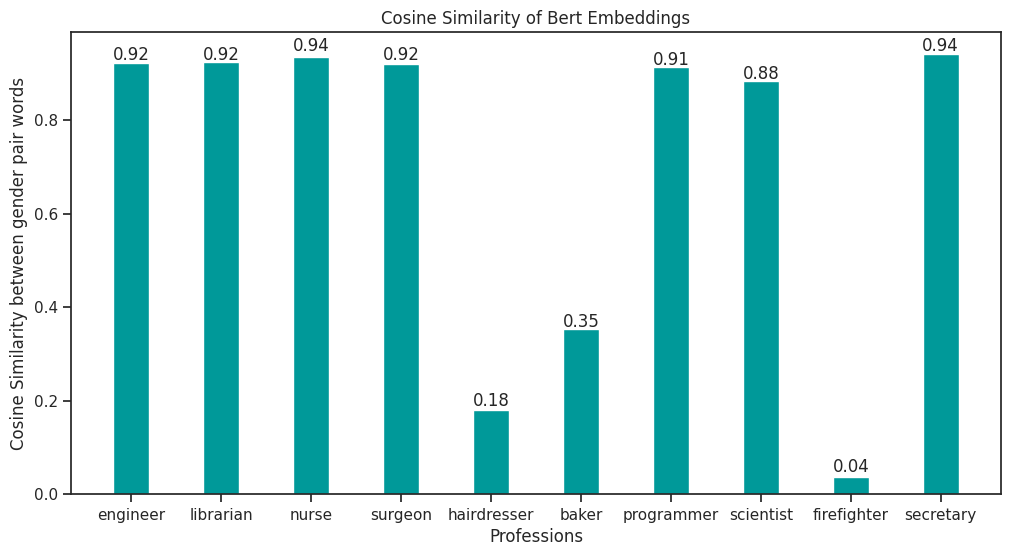

In [ ]:
import matplotlib.pyplot as plt

# Example dictionary
def visualization(data):

  # Create lists for x and y values
  x_values = list(data.keys())
  y_values = list(data.values())

  plt.figure(figsize=(12, 6))

  plt.bar(x_values, y_values, color='#009999', width=0.4)
  # plt.scatter(x_values, y_values, marker='s', s=100, color='blue')

  y_rounded_values = [round(x, 2) for x in y_values]

  for i, v in enumerate(y_rounded_values):
    plt.text(i, v, str(v), ha='center', va='bottom')


  # Add labels and title
  plt.xlabel('Professions')
  plt.ylabel('Cosine Similarity between gender pair words')
  plt.title('Cosine Similarity of Bert Embeddings')


  # Show the plot
  plt.show()
visualization(similarity_dict)